In [15]:
import torch
import clip
from PIL import Image
import glob
import numpy as np
import os

In [3]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
model, preprocess = clip.load("ViT-B/32", device=device)
print("Model loaded successfully.")
print("Device:", device)

100%|███████████████████████████████████████| 338M/338M [00:04<00:00, 73.9MiB/s]


Model loaded successfully.
Device: mps


In [ ]:
image_files = [f for f in os.listdir('Data') if f.lower().endswith('.jpg')]
image_files.sort()

In [36]:
print(image_files[0])

PHOTO-2026-06-02-06-58-12 10.jpg


In [ ]:
images = []
for file in image_files:
    im = Image.open(os.path.join("Data", file))
    images.append(im)

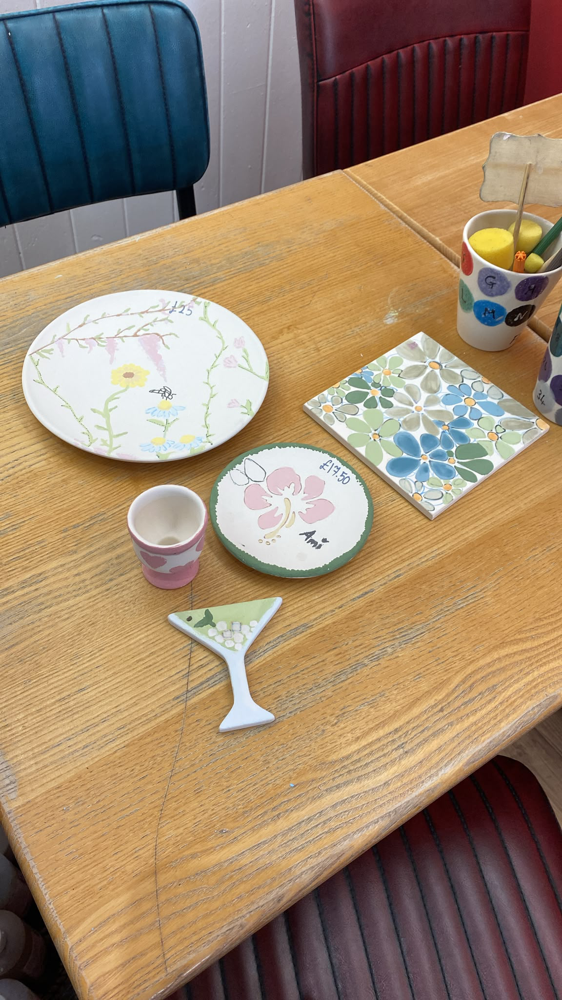

In [20]:
display(images[0])

In [21]:
preprocessed_images = []
for im in images:
    preprocessed_images.append(preprocess(im).unsqueeze(0).to(device))

In [30]:
image_input = torch.cat(preprocessed_images)
with torch.no_grad():
    image_features = model.encode_image(image_input)
image_vectors = image_features.cpu().numpy()

In [104]:
search_text = "vogue"
text = clip.tokenize([search_text]).to(device)
with torch.no_grad():
    text_vector = model.encode_text(text).cpu().numpy()
print(image_vectors[1].shape)

(512,)


In [105]:
image_vectors = image_vectors / np.linalg.norm(image_vectors, axis=1, keepdims=True)
text_vector   = text_vector   / np.linalg.norm(text_vector,   axis=1, keepdims=True)

In [106]:
similarity = (image_vectors @ text_vector.T).squeeze(-1)
top3 = np.argsort(similarity)[::-1][:3]
print(top3)
print(similarity[top3])

[31  2 20]
[0.2402 0.2102 0.2102]


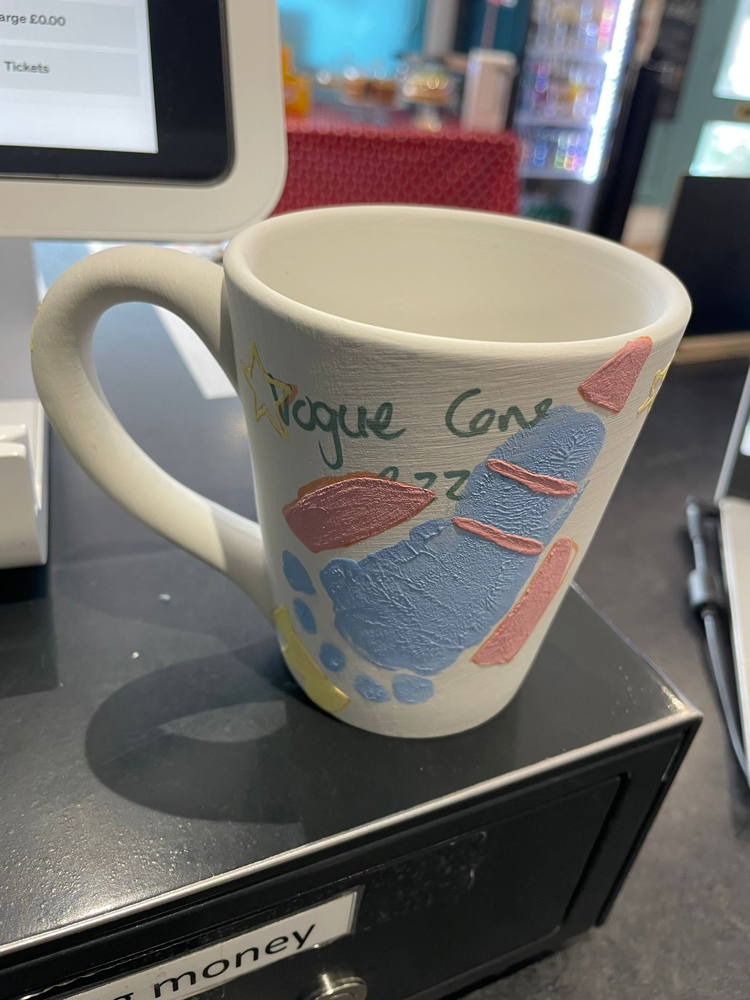

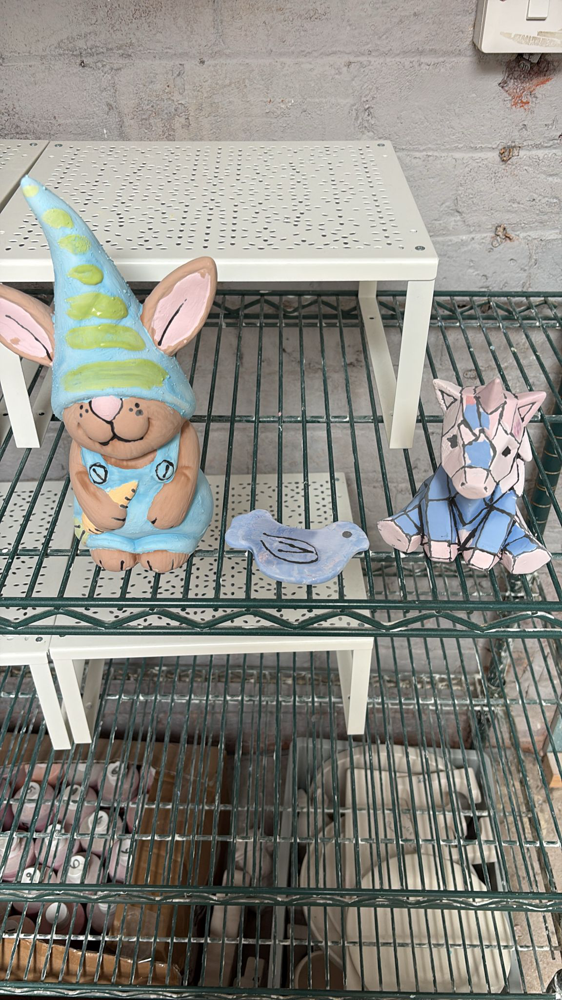

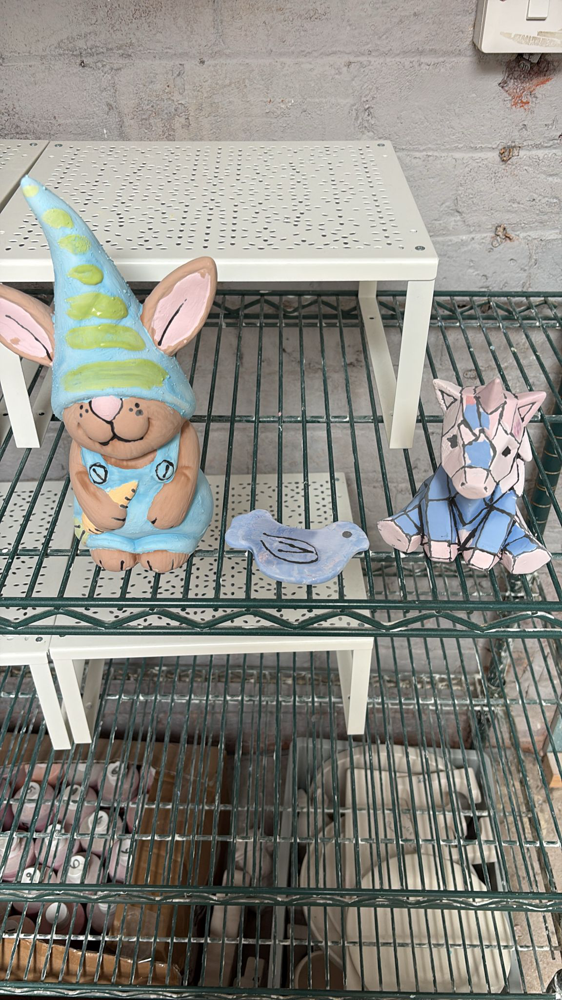

In [107]:
display(images[top3[0]])
display(images[top3[1]])
display(images[top3[2]])